# Credit Card Transactions Fraud Detection · 02 Exploratory Data Analysis

# Aim, Objective, and Motivation
- **Aim:** <u>find</u> which signals separate fraud from legit transactions.
- **Objective:** back every visual impression with a **statistical test** and turn findings into feature decisions.
- **Motivation:** good features beat fancy models — EDA tells us which features to build in notebook 03.

(!) EDA uses **`fraudTrain` only**. The test period stays unseen until the final evaluation,
otherwise design choices would be tuned to the test set.

# Outlines
1. Amount
2. Spending category
3. Time cycles: hour & day of week
4. Card holder: age, gender, city size
5. Geography: distance & state
6. Card behaviour: fraud bursts
7. Statistical tests
    - 7.1 Numeric features — Mann-Whitney U
    - 7.2 Categorical features — χ² & Cramér's V
8. Correlation
9. Summary

<!-- objective -->
## Objective

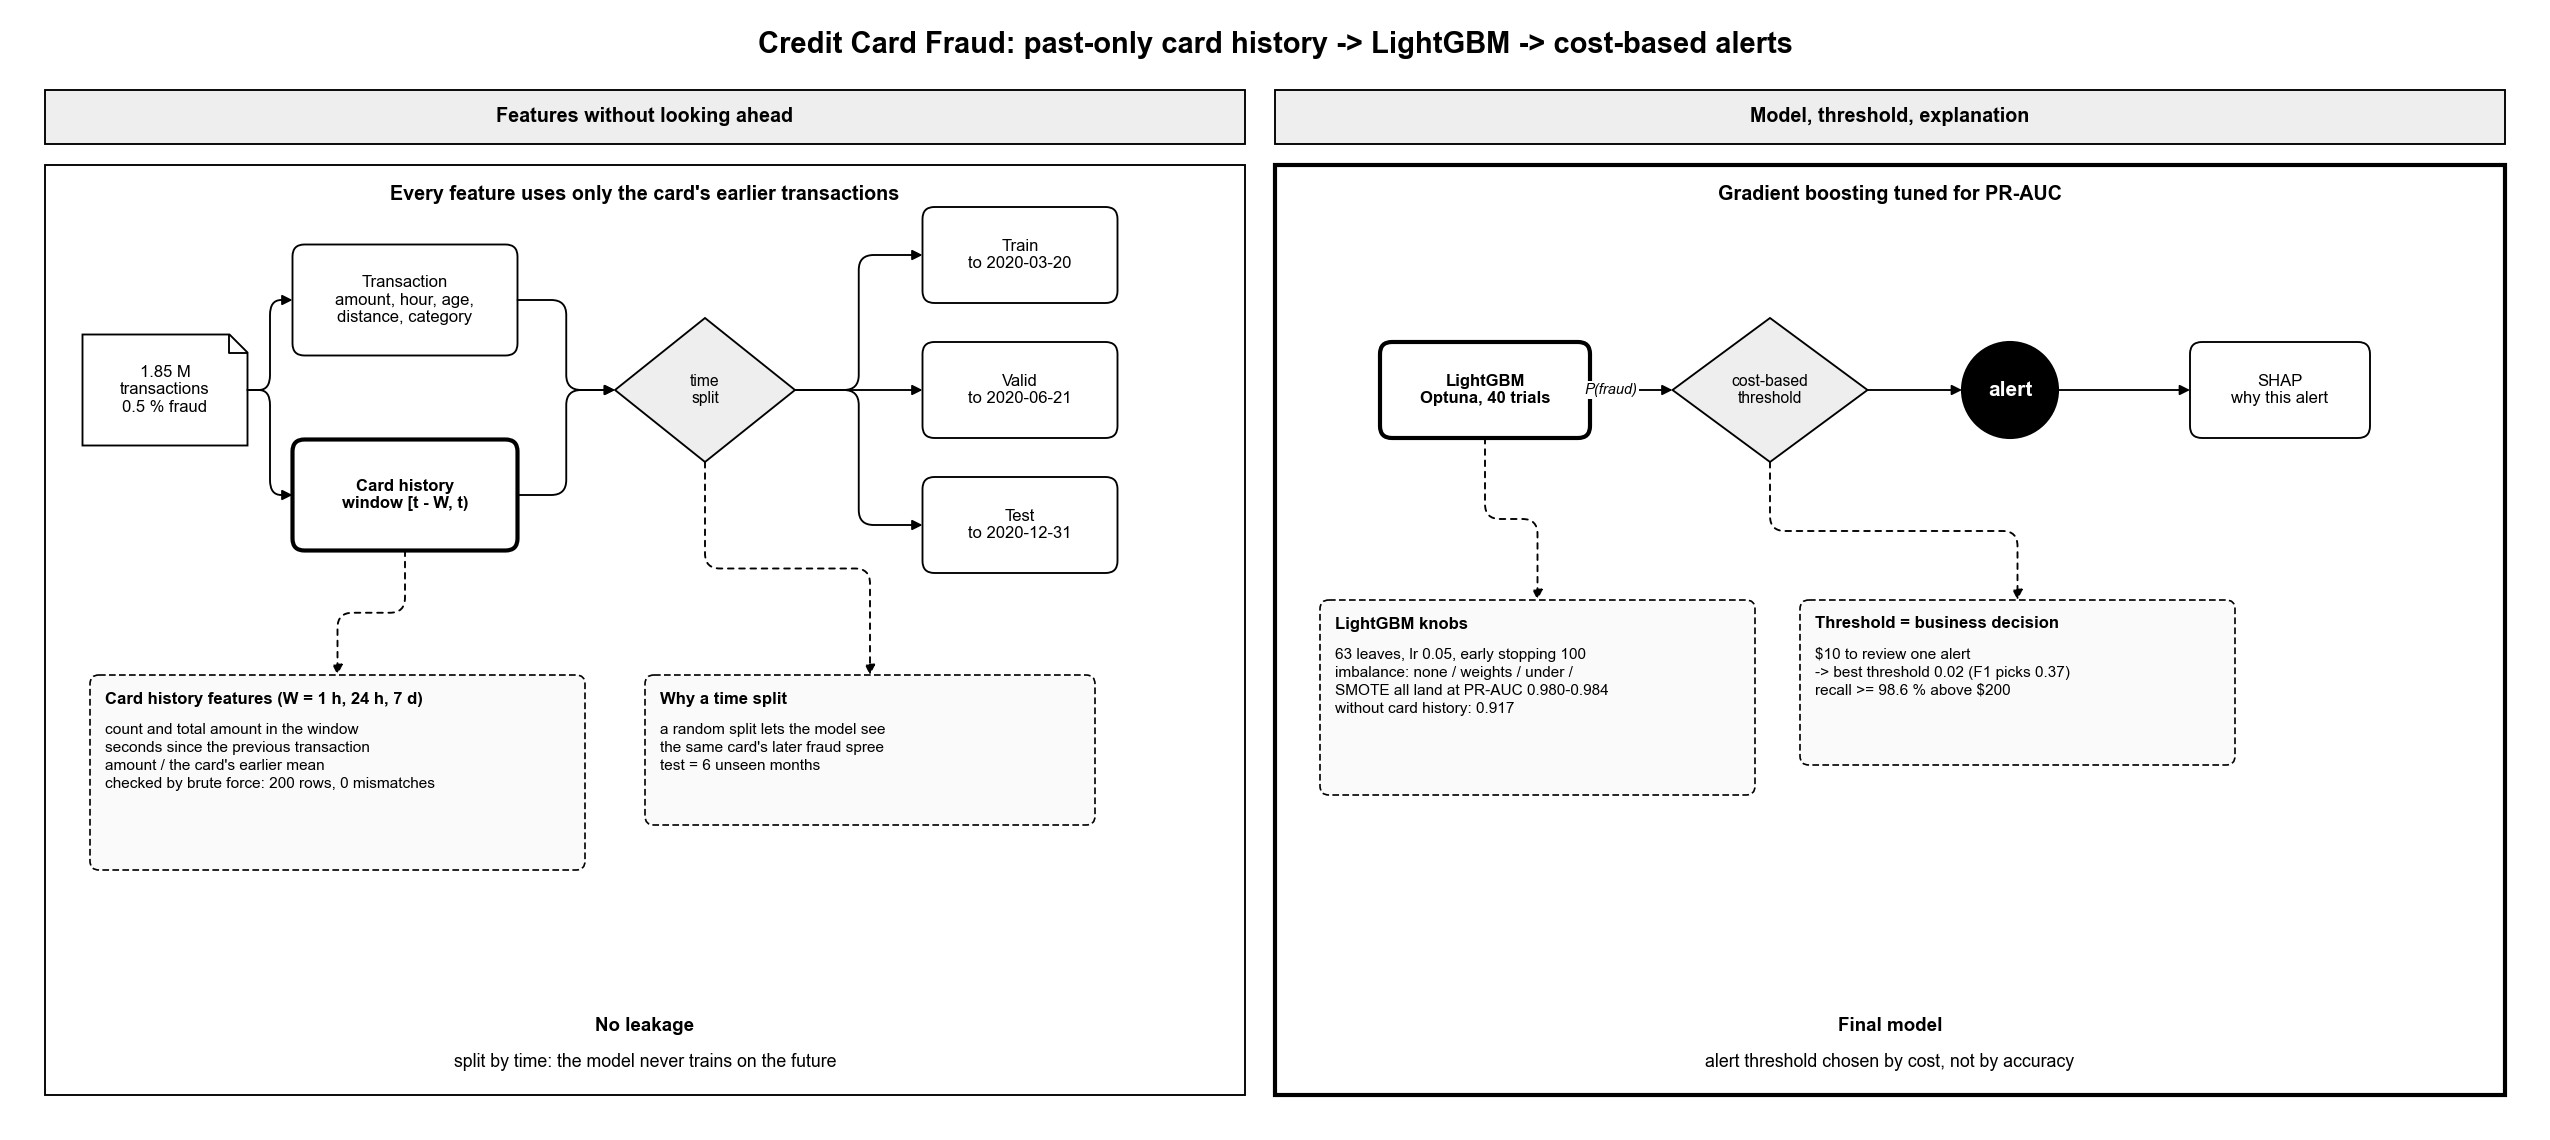

- **Problem** → about 1 in 200 card payments is fraud, and a fraud team can only review so many alerts a day
- **Why this repo** → rank every payment by fraud risk using only what the bank knew *at that moment*, then pick the alert threshold from the cost of a review, not from accuracy
- **Real-world use** → an alert queue: the riskiest payments go to an analyst (or trigger an SMS check) first; the threshold slider trades missed fraud against analyst workload

In [1]:
# ---------------------------------------------------------------- Imports
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src.config import COLORS, LABELS, TARGET
from src.data import load_raw
from src.features import build_features
from src.plotting import set_style, savefig

# ---------------------------------------------------------------- Global constants
PALETTE = {LABELS[k]: v for k, v in COLORS.items()}   # {"Legit": grey, "Fraud": red}
AMOUNT_BINS = [0, 10, 50, 100, 200, 300, 500, 800, 1000, 1500, 30000]
DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
BURST_WINDOW = (pd.Timedelta("7D"), pd.Timedelta("4D"))  # days before / after first fraud in the card timeline
NUMERIC_TESTED = ["amount", "hour", "is_night", "age", "log_city_pop", "distance_km", "secs_since_prev_txn",
                  "card_txn_count_1h", "card_txn_count_24h", "card_txn_count_7d", "card_amount_sum_24h",
                  "amount_vs_card_mean", "card_txn_index"]
CATEGORICAL_TESTED = ["category", "gender", "state", "day_of_week", "job", "merchant"]

set_style()

In [2]:
df = build_features(load_raw("train"))  # causal (past-only) features, explained in notebook 03
df["label"] = df[TARGET].map(LABELS)
fraud, legit = df[df[TARGET] == 1], df[df[TARGET] == 0]
BASE_RATE = df[TARGET].mean()

In [3]:
print(f"{len(df):,} transactions, fraud rate {BASE_RATE:.3%}")

1,296,675 transactions, fraud rate 0.579%


In [4]:
def fraud_rate_bar(col, ax, order=None, rotate=0):
    """Bar = fraud rate per value of `col`; dashed line = overall fraud rate."""
    rate = df.groupby(col, observed=True)[TARGET].mean().mul(100)
    rate = rate.reindex(order) if order is not None else rate.sort_values(ascending=False)
    ax.bar(rate.index.astype(str), rate.values, color=COLORS[1], alpha=0.85)
    ax.axhline(BASE_RATE * 100, ls="--", c="black", lw=1, label=f"overall {BASE_RATE:.2%}")
    ax.set(ylabel="fraud rate (%)", title=f"Fraud rate by {col}")
    ax.tick_params(axis="x", rotation=rotate)
    ax.legend()
    return rate

# [1/9] Amount
> **Question:** do fraudsters spend differently from normal customers?
>
> **Formula:** $\text{fraud rate}_{b} = \frac{\#\,\text{fraud in band } b}{\#\,\text{transactions in band } b}$

In [5]:
amount_summary = df.groupby("label")["amount"].describe()
money = df.groupby("label")["amount"].sum()
df["amount_band"] = pd.cut(df["amount"], AMOUNT_BINS)
band_rate = df.groupby("amount_band", observed=True)[TARGET].mean() * 100

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
sns.histplot(data=df, x="amount", hue="label", log_scale=True, bins=80, stat="density",
             common_norm=False, element="step", palette=PALETTE, ax=axes[0])
axes[0].set_title("Amount distribution (log scale)")
axes[1].bar(money.index, money.values / 1e6, color=[PALETTE[i] for i in money.index])
for i, v in enumerate(money.values):
    axes[1].text(i, v / 1e6, f"${v / 1e6:.1f}M\n({v / money.sum():.1%})", ha="center", va="bottom")
axes[1].set(title="Total money moved", ylabel="USD (millions)", ylim=(0, money.max() / 1e6 * 1.2))
axes[2].bar(band_rate.index.astype(str), band_rate.values, color=COLORS[1])
axes[2].set(title="Fraud rate by amount band", ylabel="fraud rate (%)")
axes[2].tick_params(axis="x", rotation=45)
savefig(fig, "02_amount")
plt.close(fig)  # displayed in its own cell below

In [6]:
amount_summary.round(1)

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
Fraud,7506.0,531.3,390.6,1.1,245.7,396.5,900.9,1376.0
Legit,1289169.0,67.7,154.0,1.0,9.6,47.3,82.5,28948.9


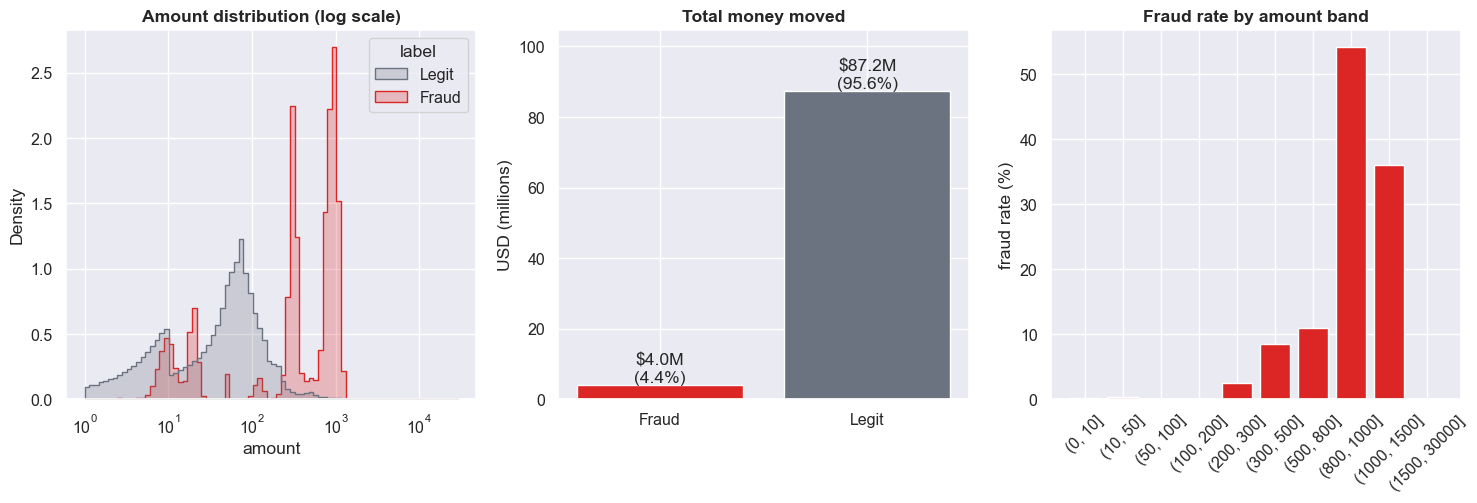

In [7]:
fig

**Answer:** yes, very differently.
- Fraud amounts form **three clusters**: small "card testing" charges (≈ \$10–25), ≈ \$300 and ≈ \$800–1,100.
  Legit spending is concentrated below \$100. The largest fraud is only \$1,376.
- Fraud is **0.6 % of transactions but 4.4 % of the money** — catching it matters financially.
- In the **\$800–1,000 band more than half of all transactions are fraud**; below \$200 fraud is almost absent.

→ The old version removed amount "outliers" with a z-test — that threw away exactly the fraud cases. We keep every row.

# [2/9] Spending category
> **Question:** are some spending categories targeted more than others?

In [8]:
mix = pd.crosstab(df["category"], df["label"], normalize="columns").mul(100)
mix["fraud_minus_legit_pp"] = mix["Fraud"] - mix["Legit"]
cat_order = df.groupby("category", observed=True)[TARGET].mean().sort_values(ascending=False).index

fig, axes = plt.subplots(2, 1, figsize=(15, 10))
fraud_rate_bar("category", axes[0], rotate=45)
sns.boxplot(data=df, x="category", y="amount", hue="label", order=cat_order, palette=PALETTE,
            showfliers=False, ax=axes[1])
axes[1].set(yscale="log", title="Amount per category: fraud vs legit (log scale)")
axes[1].tick_params(axis="x", rotation=45)
fig.tight_layout()
savefig(fig, "02_category")
plt.close(fig)  # displayed in its own cell below

In [9]:
mix.sort_values("fraud_minus_legit_pp", ascending=False).round(2)

label,Fraud,Legit,fraud_minus_legit_pp
category,,,
shopping_net,22.82,7.43,15.39
grocery_pos,23.22,9.46,13.77
misc_net,12.19,4.84,7.35
shopping_pos,11.23,8.98,2.25
travel,1.55,3.13,-1.59
grocery_net,1.79,3.52,-1.73
gas_transport,8.23,10.16,-1.93
misc_pos,3.33,6.16,-2.83
personal_care,2.93,7.02,-4.09


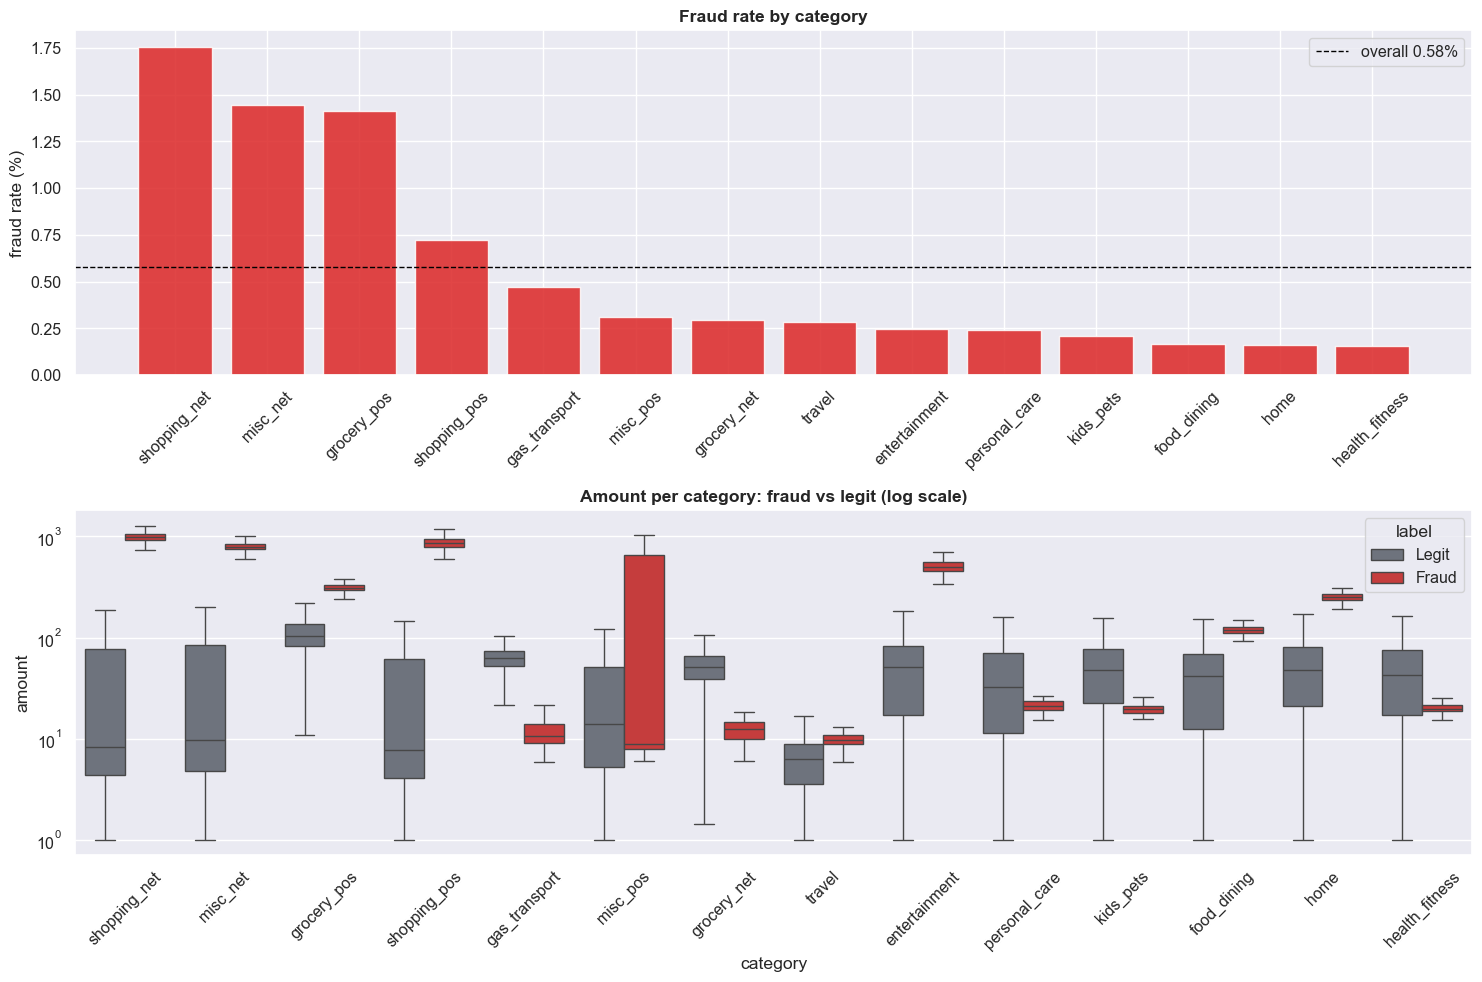

In [10]:
fig

**Answer:** yes. `shopping_net`, `grocery_pos` and `misc_net` are strongly over-represented in fraud
(+15, +14 and +7 percentage points), while home, kids/pets, food and health are rarely targeted.
Within every category fraud amounts are far higher than legit ones → **category × amount** is a strong pattern
(an \$800 grocery bill is very unusual).

# [3/9] Time cycles: hour & day of week
> **Question:** does fraud happen at particular times?

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
hour_rate = fraud_rate_bar("hour", axes[0], order=range(24))
day_rate = fraud_rate_bar("day_of_week", axes[1], order=range(7))
axes[1].set_xticks(range(7), DAYS)
savefig(fig, "02_time_cycles")
plt.close(fig)  # displayed in its own cell below

In [12]:
pd.DataFrame({"night 22-23h": [hour_rate.loc[[22, 23]].mean()],
              "night 0-3h": [hour_rate.loc[0:3].mean()],
              "day 4-21h": [hour_rate.loc[4:21].mean()]}, index=["fraud rate %"]).round(2)

,night 22-23h,night 0-3h,day 4-21h
fraud rate %,2.86,1.48,0.11


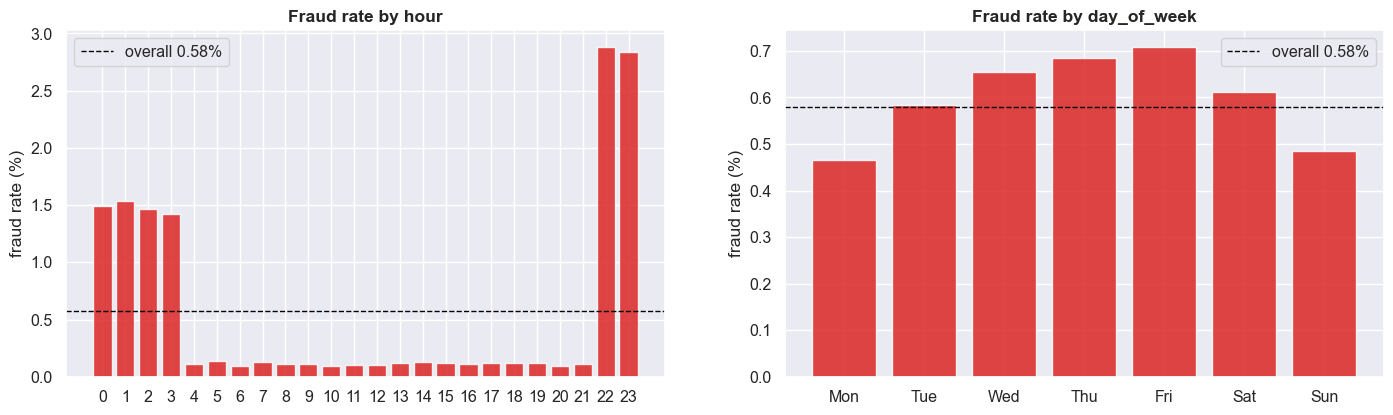

In [13]:
fig

**Answer:** yes — **hour is the strongest time signal.** At 22:00–23:59 the fraud rate is ≈ 2.9 % and at
00:00–03:59 ≈ 1.5 %, versus ≈ 0.1 % during the day: **15–30× higher at night** → motivates the `is_night` flag.
Day of week shows only mild differences (Wed–Fri slightly higher).

# [4/9] Card holder: age, gender, city size
> **Question:** are some customers more likely to be victims?

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.kdeplot(data=df, x="age", hue="label", common_norm=False, fill=True, palette=PALETTE, ax=axes[0])
axes[0].set_title("Age at transaction")
gender_rate = fraud_rate_bar("gender", axes[1])
sns.kdeplot(data=df, x="log_city_pop", hue="label", common_norm=False, fill=True, palette=PALETTE, ax=axes[2])
axes[2].set_title("City population (log)")
savefig(fig, "02_holder")
plt.close(fig)  # displayed in its own cell below

In [15]:
gender_rate.round(3)

gender
M    0.643
F    0.526
Name: is_fraud, dtype: float64

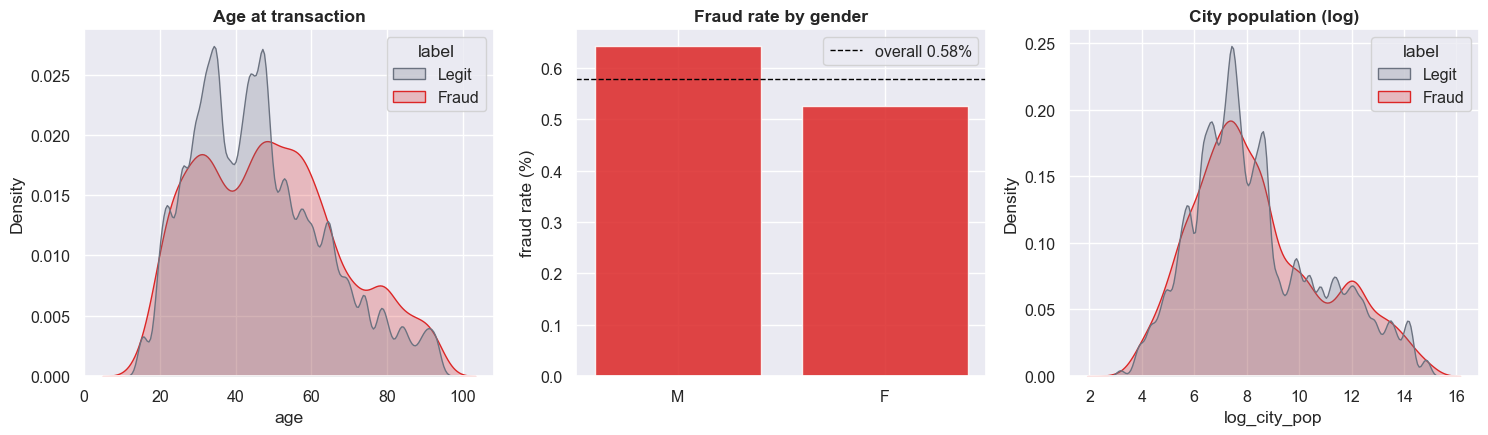

In [16]:
fig

**Answer:** only weakly. Older holders (60+) are somewhat more often victims; gender and city size show small
differences. These are weak features on their own.

# [5/9] Geography: distance & state
> **Question:** does the distance between customer and merchant, or the state, matter?
>
> **Formula (haversine distance):** $d = 2R\arcsin\sqrt{\sin^2\frac{\Delta\varphi}{2} + \cos\varphi_1\cos\varphi_2\sin^2\frac{\Delta\lambda}{2}}$, $R = 6371$ km

In [17]:
state_stats = (df.groupby("state", observed=True)[TARGET].agg(["size", "sum", "mean"])
               .sort_values("mean", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
sns.kdeplot(data=df, x="distance_km", hue="label", common_norm=False, fill=True, palette=PALETTE, ax=axes[0])
axes[0].set_title("Distance card holder → merchant (km)")
fraud_rate_bar("state", axes[1], rotate=90)
savefig(fig, "02_geography")
plt.close(fig)  # displayed in its own cell below

In [18]:
state_stats.head(8)

,size,sum,mean
state,,,
DE,9,9,1.000000
RI,550,15,0.027273
AK,2120,36,0.016981
NV,5607,47,0.008382
CO,13880,113,0.008141
OR,18597,149,0.008012
TN,17554,140,0.007975
NE,24168,180,0.007448


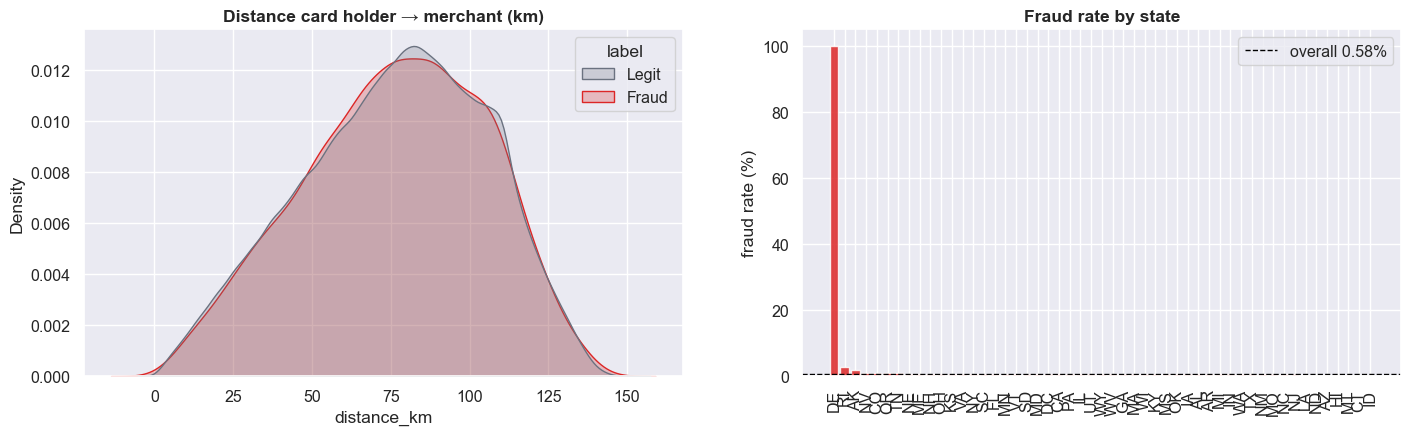

In [19]:
fig

**Answer:** no.
- Distance to merchant has **no signal**: the simulator places merchants at random around the holder
  (real data would likely differ). It is kept so the model can confirm this.
- The highest state fraud rates come from states with very few transactions (DE: 9 transactions, all fraud)
  → noise, not signal. **State is not used as a feature.**

# [6/9] Card behaviour: fraud bursts
> **Question:** does a card behave differently when it is being defrauded?

In [20]:
burst_summary = df.groupby("label")[["secs_since_prev_txn", "card_txn_count_24h", "amount_vs_card_mean"]].median()

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.histplot(data=df, x=np.log10(df["secs_since_prev_txn"].clip(lower=1)), hue="label", bins=60,
             stat="density", common_norm=False, element="step", palette=PALETTE, ax=axes[0])
axes[0].set(title="Time since card's previous transaction", xlabel="log10(seconds)")
sns.boxplot(data=df, x="label", y="card_txn_count_24h", hue="label", legend=False, palette=PALETTE,
            showfliers=False, ax=axes[1])
axes[1].set_title("Card transactions in previous 24h")
sns.boxplot(data=df, x="label", y=np.log10(df["amount_vs_card_mean"].clip(lower=1e-3)), hue="label",
            legend=False, palette=PALETTE, showfliers=False, ax=axes[2])
axes[2].set(title="Amount vs card's usual amount", ylabel="log10(ratio)")
savefig(fig, "02_card_behaviour")
plt.close(fig)  # displayed in its own cell below

In [21]:
burst_summary.round(2)

,secs_since_prev_txn,card_txn_count_24h,amount_vs_card_mean
label,,,
Fraud,4908.0,4.0,5.23
Legit,16623.0,3.0,0.66


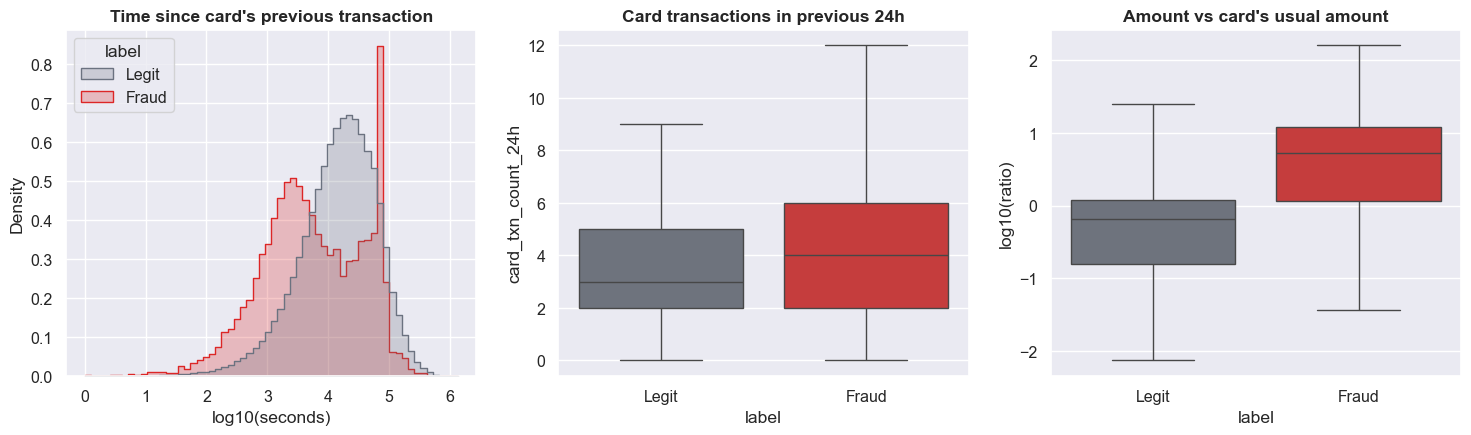

In [22]:
fig

## 6.1 One card's timeline
> **Objective:** <u>see</u> a fraud burst on a real example — a card with a long normal history before its first fraud.

In [23]:
first_frauds = fraud.sort_values("trans_time").groupby("card_id", observed=True).head(1)
example_card = first_frauds.sort_values("card_txn_index")["card_id"].iloc[len(first_frauds) // 2]
card = df[df["card_id"] == example_card].set_index("trans_time")
first_fraud = card[card[TARGET] == 1].index.min()
window = card.loc[first_fraud - BURST_WINDOW[0]: first_fraud + BURST_WINDOW[1]]

fig, ax = plt.subplots(figsize=(15, 4))
for k in (0, 1):
    w = window[window[TARGET] == k]
    ax.scatter(w.index, w["amount"], c=COLORS[k], s=30 if k else 16, alpha=1 if k else 0.6, label=LABELS[k])
ax.legend()
ax.set(yscale="log", ylabel="amount (USD, log)",
       title=f"Timeline of one card around its first fraud (card …{str(example_card)[-4:]})")
savefig(fig, "02_card_timeline")
plt.close(fig)  # displayed in its own cell below

In [24]:
window[["category", "amount", TARGET]].query(f"{TARGET} == 1")

,category,amount,is_fraud
trans_time,,,
2020-03-31 01:03:59,gas_transport,8.02,1
2020-03-31 03:39:47,grocery_net,9.25,1
2020-03-31 13:53:45,shopping_pos,995.49,1
2020-03-31 14:19:20,shopping_pos,923.96,1
2020-03-31 22:27:45,shopping_net,952.54,1
2020-03-31 22:43:56,shopping_net,914.09,1
2020-03-31 22:51:52,shopping_net,1010.04,1
2020-03-31 22:59:35,shopping_net,1058.80,1
2020-03-31 23:21:20,entertainment,383.42,1


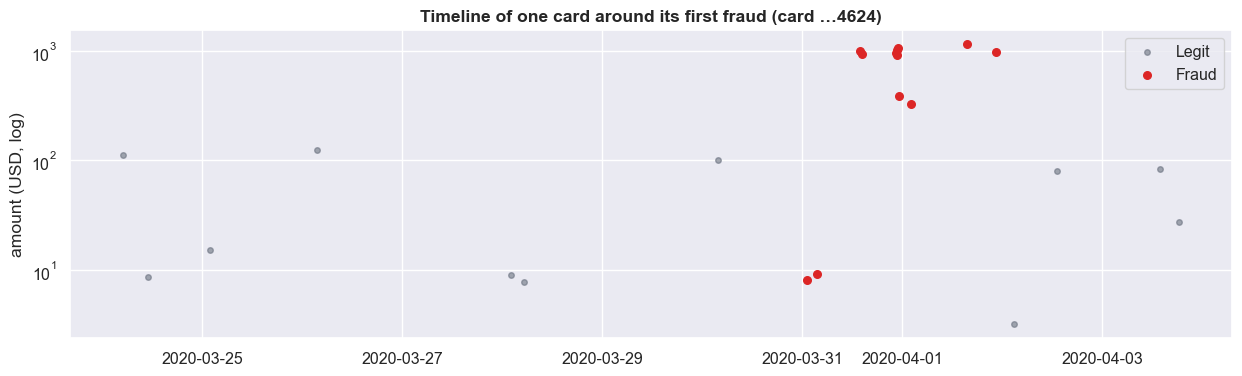

In [25]:
fig

**Answer:** yes. A compromised card shows sparse normal purchases, then a **burst of fraud over 1–2 days** —
two small "testing" charges first, then many \$300–1,100 charges close together — and afterwards returns to normal.
Fraud happens sooner after the previous transaction (median ≈ 1.4 h vs ≈ 4.6 h) at amounts ≈ 5× the card's usual.

# [7/9] Statistical tests
With 1.3M rows *every* p-value is tiny, so the **effect size** is what tells us whether a feature is useful.

## 7.1 Numeric features — Mann-Whitney U
> **Question:** do fraud and legit values of each numeric feature come from the same distribution?
> - $H_0$: same distribution · $H_1$: different distributions (two-sided). Non-parametric — amounts are far from normal.
> - **Effect size (rank-biserial):** $r = \frac{2U}{n_{fraud}\, n_{legit}} - 1 \in [-1, 1]$ — |r| ≥ 0.3 medium, ≥ 0.5 large;
>   r > 0 means higher values for fraud.

In [26]:
rows = []
for col in NUMERIC_TESTED:
    a, b = fraud[col].dropna(), legit[col].dropna()
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    rows.append({"feature": col, "fraud_median": a.median(), "legit_median": b.median(),
                 "p_value": p, "rank_biserial_r": 2 * u / (len(a) * len(b)) - 1})
mann_whitney = pd.DataFrame(rows).sort_values("rank_biserial_r", key=abs, ascending=False)

In [27]:
mann_whitney.round(3)

,feature,fraud_median,legit_median,p_value,rank_biserial_r
10,card_amount_sum_24h,1674.155,171.140,0.000,0.729
0,amount,396.505,47.280,0.000,0.669
2,is_night,1.000,0.000,0.000,0.616
11,amount_vs_card_mean,5.230,0.664,0.000,0.615
6,secs_since_prev_txn,4908.000,16623.000,0.000,-0.298
12,card_txn_index,438.000,779.000,0.000,-0.292
9,card_txn_count_7d,17.000,23.000,0.000,-0.292
7,card_txn_count_1h,0.000,0.000,0.000,0.291
1,hour,22.000,14.000,0.000,0.170
8,card_txn_count_24h,4.000,3.000,0.000,0.134


## 7.2 Categorical features — χ² & Cramér's V
> **Question:** is each categorical feature associated with fraud?
> - $H_0$: feature and `is_fraud` are independent.
> - **Effect size (Cramér's V):** $V = \sqrt{\frac{\chi^2}{n\,(\min(r, c) - 1)}} \in [0, 1]$ — 0 = no association.

In [28]:
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2, p, _, _ = stats.chi2_contingency(table)
    n = table.to_numpy().sum()
    return chi2, p, np.sqrt(chi2 / (n * (min(table.shape) - 1)))


rows = []
for col in CATEGORICAL_TESTED:
    chi2, p, v = cramers_v(df[col], df[TARGET])
    rows.append({"feature": col, "n_levels": df[col].nunique(), "chi2": chi2, "p_value": p, "cramers_v": v})
chi_square = pd.DataFrame(rows).sort_values("cramers_v", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
r = mann_whitney.set_index("feature")["rank_biserial_r"].sort_values()
axes[0].barh(r.index, r.values, color=[COLORS[1] if v > 0 else COLORS[0] for v in r.values])
axes[0].axvline(0, c="black", lw=0.8)
axes[0].set(title="Mann-Whitney effect size (rank-biserial r)", xlabel="← lower for fraud | higher for fraud →")
v = chi_square.set_index("feature")["cramers_v"].sort_values()
axes[1].barh(v.index, v.values, color=COLORS[1])
axes[1].set(title="Cramér's V with is_fraud", xlabel="association strength")
savefig(fig, "02_stat_tests")
plt.close(fig)  # displayed in its own cell below

In [29]:
chi_square.round(4)

,feature,n_levels,chi2,p_value,cramers_v
4,job,494,39165.6185,0.0,0.1738
5,merchant,693,6929.5861,0.0,0.0731
0,category,14,6486.0033,0.0,0.0707
2,state,51,1869.3404,0.0,0.0380
3,day_of_week,7,185.5129,0.0,0.0120
1,gender,2,75.5146,0.0,0.0076


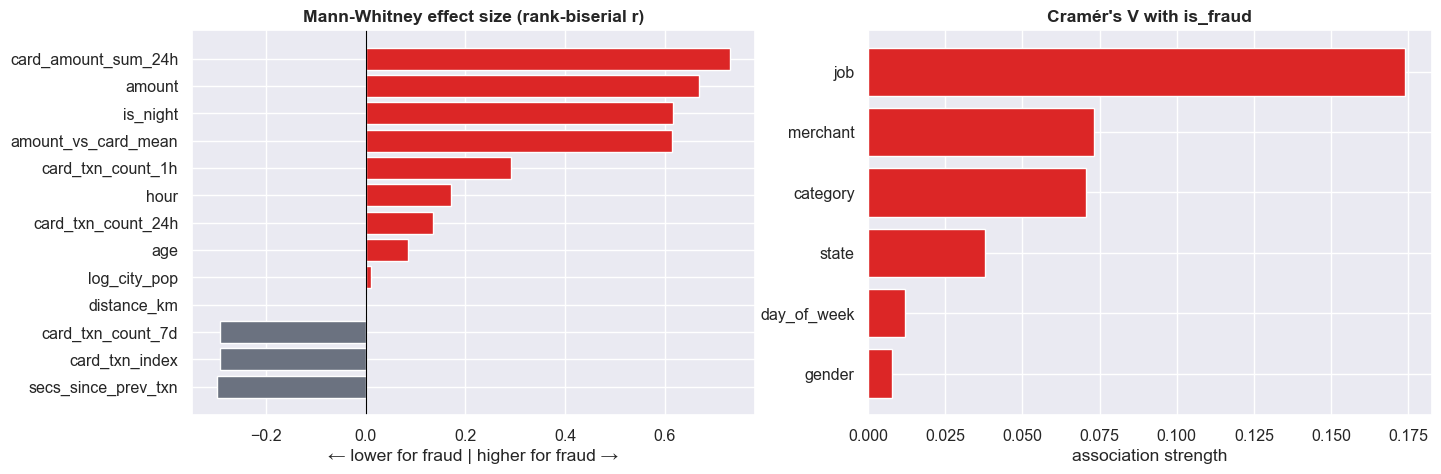

In [30]:
fig

**Answer:**
- Largest effects: **money spent on the card in the last 24h** (r = 0.73), **amount** (0.67),
  **night time** (0.62) and **amount vs the card's usual amount** (0.62).
- Fraud comes **sooner after the previous transaction** (r = −0.30) — the burst pattern.
- `distance_km` and `log_city_pop` are **not significant** (p > 0.1) → no signal.
- `job` has the highest Cramér's V (0.17), but with 494 levels many jobs belong to only one or two holders, so it acts like
  a **card identifier**: a model would memorise *which customers* were defrauded instead of learning *what fraud looks like*
  and fail on new customers. Cramér's V is also inflated by many levels. Same for `merchant` → both dropped.
- `category` (14 levels, V = 0.07) is the useful categorical feature.

# [8/9] Correlation
> **Question:** which features are redundant with each other?
>
> **Formula (Spearman):** $\rho = 1 - \frac{6\sum d_i^2}{n(n^2-1)}$, $d_i$ = rank difference — robust to skew and outliers.

In [31]:
corr = df[NUMERIC_TESTED + [TARGET]].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, mask=mask, cmap="RdGy_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 8}, ax=ax)
ax.set_title("Spearman correlation")
savefig(fig, "02_correlation")
plt.close(fig)  # displayed in its own cell below

In [32]:
corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3)

is_night               0.110
card_amount_sum_24h    0.096
amount                 0.088
amount_vs_card_mean    0.080
card_txn_count_1h      0.060
secs_since_prev_txn   -0.039
card_txn_index        -0.038
card_txn_count_7d     -0.038
hour                   0.022
card_txn_count_24h     0.018
age                    0.011
log_city_pop           0.001
distance_km            0.000
Name: is_fraud, dtype: float64

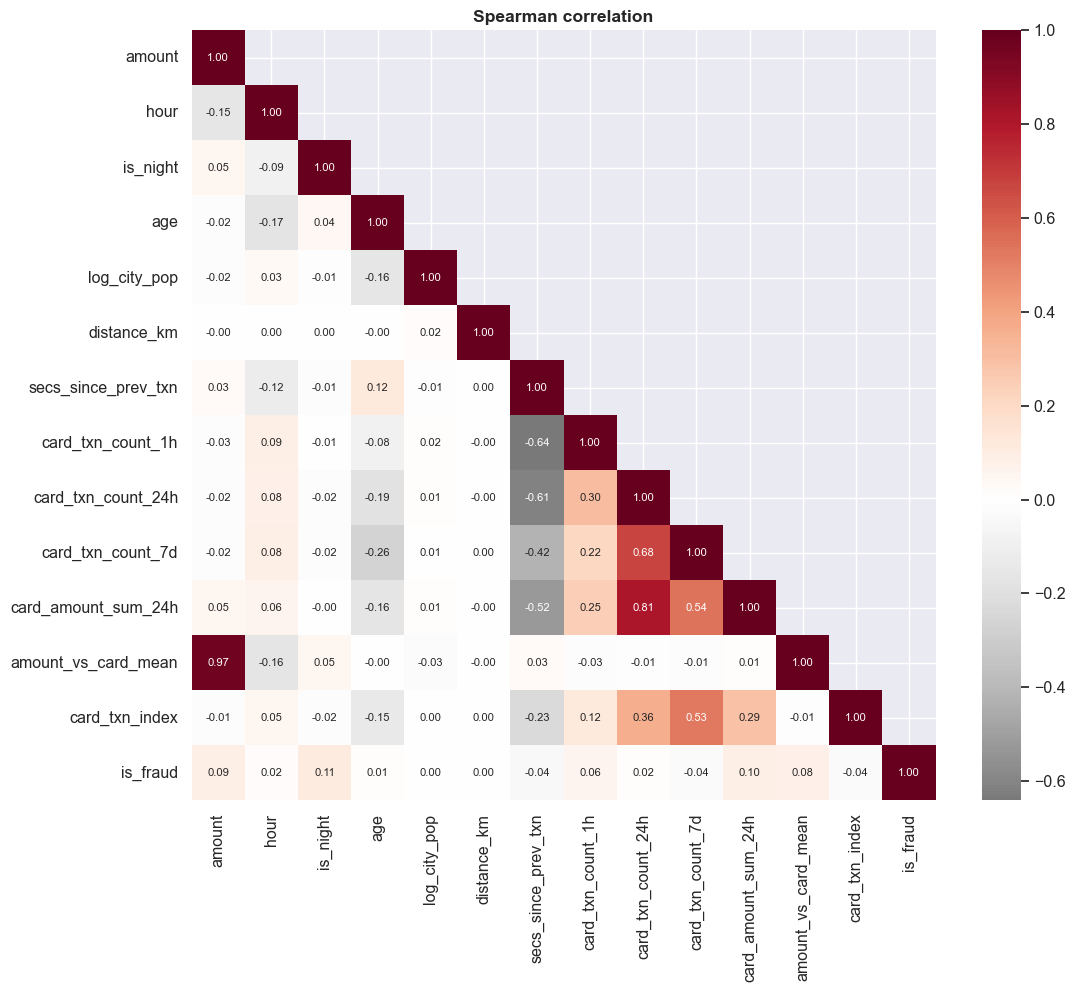

In [33]:
fig

**Answer:** the card-history windows are correlated with each other (expected) — fine for tree models, a reason to
regularise linear models. No single feature is strongly correlated with `is_fraud` (fraud is rare, so linear correlation
is small by construction) → we need models that combine features **non-linearly**.

# [9/9] Summary
| Signal | Strength | Feature(s) |
|---|---|---|
| High spending on the card in the last 24h | ★★★ | `card_amount_sum_24h` |
| Unusually large amount, esp. \$300–1,100 | ★★★ | `amount`, `log_amount` |
| Amount far above the card's usual spend | ★★★ | `amount_vs_card_mean` |
| Night time (22:00–04:00) | ★★★ | `hour`, `is_night` |
| Burst of activity on the card | ★★ | `secs_since_prev_txn`, `card_txn_count_*` |
| Category (online shopping, grocery) | ★★ | `category` |
| Age | ★ | `age` |
| Distance, city size, gender | ~ | kept, the model decides |
| State, merchant, job | noise / memorisation risk | dropped |